In [ ]:
# Step 1: Load and Prepare the Data
#First, I will load my Sleep Debt dataset and check its size, columns, missing values, and duplicate rows.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/bedtime_screentime_sleep_debt.csv')

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Dataset loaded successfully!
Rows and columns: (8500, 18)


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0.0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92.0,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45.0,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97.0,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0.0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt



Column names:
['user_id', 'age', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score', 'sleep_debt_category']

Missing values:
user_id                      0
age                          0
gender                       0
occupation_type              0
chronotype                   0
bedtime_phone_minutes        0
primary_bedtime_app         26
screen_brightness_pct        0
blue_light_filter_active     0
caffeine_post_5pm_mg        21
physical_activity_min        0
sleep_latency_min           22
total_sleep_hours            0
deep_sleep_pct               0
rem_sleep_pct                0
morning_alarm_snoozes        0
next_day_fatigue_score       0
sleep_debt_category          0
dtype: int64

Duplicate rows: 0


In [ ]:
#Handling Missing Values and Duplicates
# Remove duplicate rows
# Fill missing numerical values with median
# Fill missing categorical values with mode

In [ ]:

#Duplication handle.
df = df.drop_duplicates()
#Missing:
df['caffeine_post_5pm_mg'] = df['caffeine_post_5pm_mg'].fillna(df['caffeine_post_5pm_mg'].median())
df['sleep_latency_min'] = df['sleep_latency_min'].fillna(df['sleep_latency_min'].median())

df['primary_bedtime_app'] = df['primary_bedtime_app'].fillna(
    df['primary_bedtime_app'].mode()[0]
)

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("Dataset shape after cleaning:", df.shape)


Missing values after cleaning:
0
Dataset shape after cleaning: (8500, 18)


In [ ]:
#Target Class Distribution
#The target variable is sleep_debt_category.


sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64

Class percentages:
sleep_debt_category
Moderate Debt        52.49
Mild Deficit         23.58
Optimal Recovery     16.32
Severe Sleep Debt     7.61
Name: proportion, dtype: float64


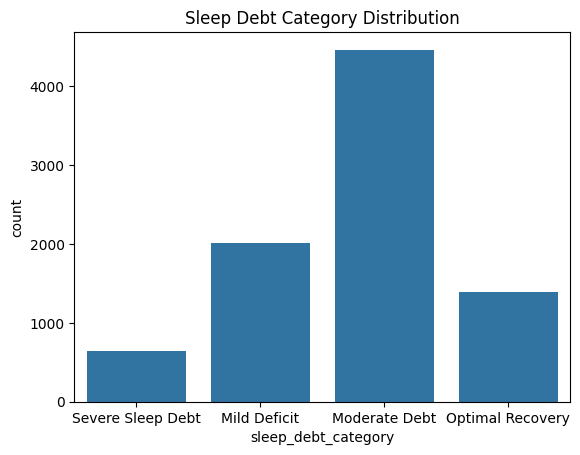

In [ ]:

print(df['sleep_debt_category'].value_counts())

print("\nClass percentages:")
print((df['sleep_debt_category'].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x='sleep_debt_category')
plt.title('Sleep Debt Category Distribution')
plt.show()


In [ ]:
#Encoding, Train-Test Split, and Scaling
#Convert categorical features into numerical values using one-hot encoding and separate the target variable from the input features.
#Spliting the data into 80% training data and 20% testing data using stratification.
#Finally,using StandardScaler, fitting it only on the training data to avoid data leakage.

In [ ]:
df = df.drop(columns=['user_id'])
# Separate features and target
X = df.drop(columns=['sleep_debt_category'])
y = df['sleep_debt_category']

# Convert text columns into numbers
X = pd.get_dummies(X, drop_first=False, dtype=int)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Training target distribution:")
print(y_train.value_counts())


Training rows: 6800
Testing rows: 1700
Number of features: 29
Training target distribution:
sleep_debt_category
Moderate Debt        3569
Mild Deficit         1603
Optimal Recovery     1110
Severe Sleep Debt     518
Name: count, dtype: int64


In [ ]:
#Step 2: K-Nearest Neighbors (KNN)
#First i will train a KNN model using 5 neighbors.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))


KNN Accuracy: 0.7188235294117648


In [ ]:
#Then we will test odd values of K from 1 to 15, compare their accuracies, and select the best K.

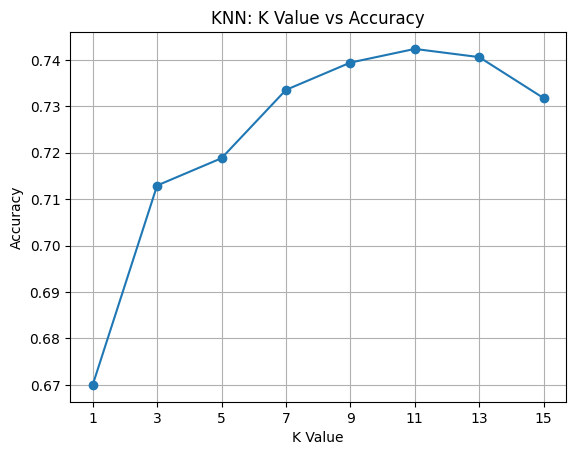

Best K: 11
Best K Accuracy: 0.7423529411764705


In [ ]:

k_values = range(1, 16, 2)
accuracies = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, predictions))

plt.plot(list(k_values), accuracies, marker='o')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.title('KNN: K Value vs Accuracy')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

best_k = list(k_values)[accuracies.index(max(accuracies))]
print("Best K:", best_k)
print("Best K Accuracy:", max(accuracies))


In [ ]:
#Step 3: Decision Tree Classifier

In [ ]:
from sklearn.tree import DecisionTreeClassifier
depth_values = [2, 3, 5, 10, None]
tree_accuracies = []
for depth in depth_values:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)

    predictions = tree.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)
    tree_accuracies.append(accuracy)

    print("Max depth:", depth, "| Accuracy:", accuracy)

best_depth = depth_values[tree_accuracies.index(max(tree_accuracies))]
print("\nBest max_depth:", best_depth)
print("Best accuracy:", max(tree_accuracies))


Max depth: 2 | Accuracy: 0.9982352941176471
Max depth: 3 | Accuracy: 1.0
Max depth: 5 | Accuracy: 1.0
Max depth: 10 | Accuracy: 1.0
Max depth: None | Accuracy: 1.0

Best max_depth: 3
Best accuracy: 1.0


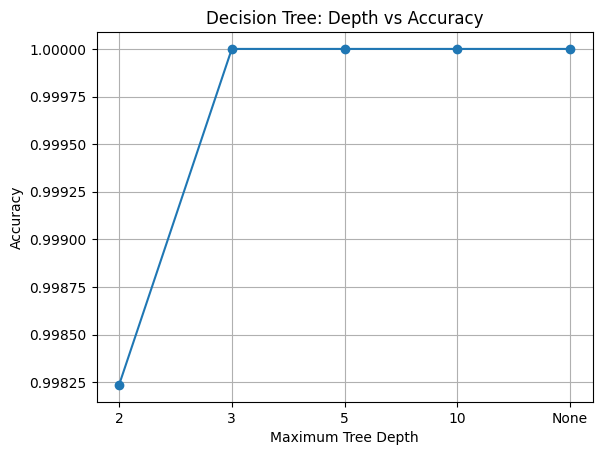

In [ ]:
#Graph:

depth_labels = [str(d) for d in depth_values]

plt.plot(depth_labels, tree_accuracies, marker='o')
plt.xlabel('Maximum Tree Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Depth vs Accuracy')
plt.grid(True)
plt.show()


In [ ]:
#Step 4: Logistic Regression

In [ ]:

from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)
y_pred_log = log_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_log))


Logistic Regression Accuracy: 0.9805882352941176


In [ ]:
probabilities = log_model.predict_proba(X_test_scaled[:5])

print("Classes:", log_model.classes_)
print("\nProbabilities for first 5 test rows:")
print(np.round(probabilities, 3))


Classes: ['Mild Deficit' 'Moderate Debt' 'Optimal Recovery' 'Severe Sleep Debt']

Probabilities for first 5 test rows:
[[0.963 0.002 0.034 0.   ]
 [0.    1.    0.    0.   ]
 [0.055 0.    0.945 0.   ]
 [0.842 0.    0.157 0.   ]
 [0.    0.04  0.    0.96 ]]


In [ ]:
#Step 5: Model Evaluation and Comparison

In [ ]:
# Best KNN
knn = KNeighborsClassifier(n_neighbors=11)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

# Best Decision Tree
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)

# Logistic Regression
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)
y_pred_log = log_model.predict(X_test_scaled)

print("Final models trained successfully!")


Final models trained successfully!


In [ ]:

from sklearn.metrics import confusion_matrix, classification_report

models = {
    "KNN (K=11)": (knn, X_test_scaled, y_pred_knn),
    "Decision Tree (depth=3)": (tree, X_test, y_pred_tree),
    "Logistic Regression": (log_model, X_test_scaled, y_pred_log)
}

for name, (model, X_data, predictions) in models.items():
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))
    print("\nClassification Report:")
    print(classification_report(y_test, predictions, zero_division=0))



 KNN (K=11)
Accuracy: 0.7423529411764705

Confusion Matrix:
[[228 109  64   0]
 [ 91 792   6   4]
 [ 95   6 176   0]
 [  0  63   0  66]]

Classification Report:
                   precision    recall  f1-score   support

     Mild Deficit       0.55      0.57      0.56       401
    Moderate Debt       0.82      0.89      0.85       893
 Optimal Recovery       0.72      0.64      0.67       277
Severe Sleep Debt       0.94      0.51      0.66       129

         accuracy                           0.74      1700
        macro avg       0.76      0.65      0.69      1700
     weighted avg       0.75      0.74      0.74      1700


 Decision Tree (depth=3)
Accuracy: 1.0

Confusion Matrix:
[[401   0   0   0]
 [  0 893   0   0]
 [  0   0 277   0]
 [  0   0   0 129]]

Classification Report:
                   precision    recall  f1-score   support

     Mild Deficit       1.00      1.00      1.00       401
    Moderate Debt       1.00      1.00      1.00       893
 Optimal Recovery       1

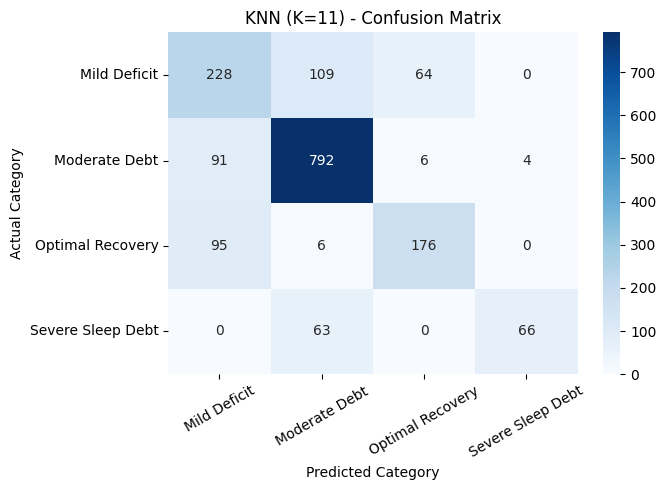

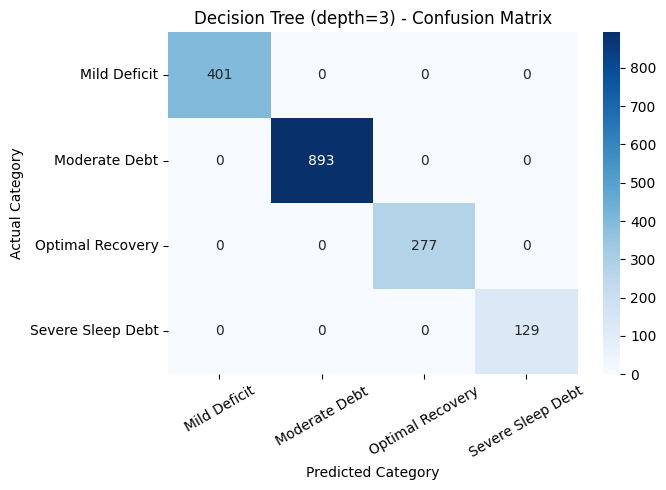

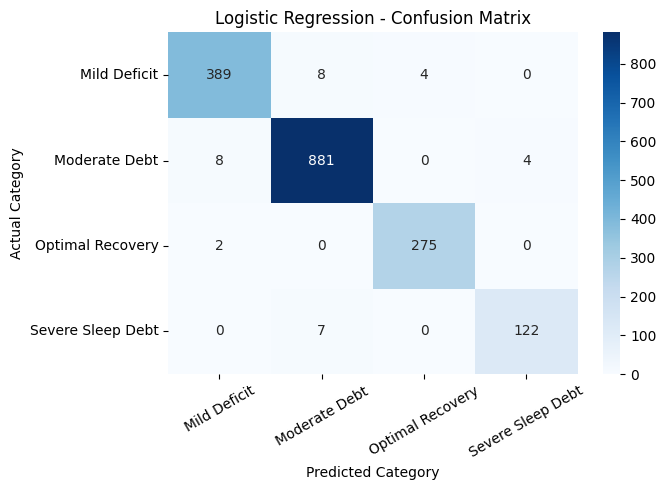

In [ ]:

for name, (model, X_data, predictions) in models.items():
    cm = confusion_matrix(y_test, predictions, labels=model.classes_)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=model.classes_,
        yticklabels=model.classes_
    )

    plt.title(name + ' - Confusion Matrix')
    plt.xlabel('Predicted Category')
    plt.ylabel('Actual Category')
    plt.xticks(rotation=30)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


In [ ]:

results = []

for name, (model, X_data, predictions) in models.items():
    report = classification_report(
        y_test, predictions, output_dict=True, zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": report["macro avg"]["precision"],
        "Recall": report["macro avg"]["recall"],
        "F1": report["macro avg"]["f1-score"]
    })

comparison = pd.DataFrame(results)

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1
0,KNN (K=11),0.7424,0.7564,0.6506,0.6865
1,Decision Tree (depth=3),1.0000,1.0000,1.0000,1.0000
2,Logistic Regression,0.9806,0.9780,0.9738,0.9759


In [ ]:
#Step 6: Evaluations:
#Which Model Is Best and Why?

#The Decision Tree is the best-performing model in my current results.
#It achieved 100% accuracy, precision, recall, and F1-score on the test data.
#The Decision Tree gave the best results, and a maximum depth of 3 was sufficient to achieve perfect accuracy.
#(I am not sure that it would be best work in real-world as in last session discuss that no model is perfect).

In [ ]:
# - Which mistake is worse for YOUR problem: a false positive
#    or a false negative? So which metric matters more
#   (precision or recall)?

#For my sleep debt problem, I consider a false negative for Severe Sleep Debt more concerning.
#It means the model misses a person who belongs to the severe category.
#A false positive means the model incorrectly predicts Severe Sleep Debt for someone in another category.

#Therefore, recall(TP/(TP+FN)) for Severe Sleep Debt is an important metric because it measures how many actual severe cases the model correctly identifies.
#Logistic Regression achieved ~97% recall for this category, while KNN achieved ~65%.
#These results show that Logistic Regression identifies severe cases more effectively than KNN while Decision tree is best of both with 100% recall.

In [ ]:
#Where does the best model make mistakes?

# Decision Tree confusion matrix is:
# Actual category |	Correct predictions
# Mild Deficit |	401/401
# Moderate Debt |	893/893
# Optimal Recovery	| 277/277
# Severe Sleep Debt	| 129/129

In [ ]:
#Extra Work:(Bonus);

#Is Accuracy Alone Misleading?

#Accuracy alone may be misleading when the target classes
#(like in SleepDebt we have four target classes: Mild Deficit, Moderate Debt, Optimal Recovery, Severe Sleep Debt)
#are imbalanced because it does not show how well the model performs on each class.
#(Classes Inbalance Proof):
# sleep_debt_category   |     Percentage
# Moderate Debt    |    52.49
# Mild Deficit     |    23.58
# Optimal Recovery |    16.32
# Severe Sleep Debt|     7.61
#In our(SleepDebt) results, KNN achieved 74.24% accuracy, but its recall for Severe Sleep Debt was only 51%. It missed 63 actual severe cases.

#Logistic Regression achieved 98.06% accuracy and 95% recall for Severe Sleep Debt.
# Its macro F1-score was 97.59%, showing strong performance across the four classes. The Decision Tree achieved perfect scores,
# but I should investigate this result before drawing a final conclusion.
# Comparing accuracy with precision, recall, F1-score, and the confusion matrix gives a more complete understanding of model performance.
#(In-short Accuracy is mostly useful when both all classes have equal part(balanced classes));